# Experiment No. 6 — Predictive Analytics using Linear Regression and Model Performance Evaluation

- **Name:** Abhigyan Dubey
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250059
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** To develop a Linear Regression model using Python for predicting continuous outcomes and evaluate its performance using appropriate regression metrics.

**Dataset:** California Housing Dataset, loaded via `sklearn.datasets.fetch_california_housing()`.

---

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 1: Select and load the dataset

In [2]:
# Step 1: Select and load the dataset
housing = fetch_california_housing()

df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

df["MedHouseVal"] = housing.target

print("Step 1: Dataset Loaded Successfully")
print(df.head())

Step 1: Dataset Loaded Successfully
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


## Step 2: Import libraries and check dataset

In [3]:
# Step 2: Import libraries and check dataset
print("\nStep 2: Dataset Information")
print("Shape:", df.shape)
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


Step 2: Dataset Information
Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


## Step 3: Data preprocessing and feature selection

In [4]:
# Step 3: Data preprocessing and feature selection
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("\nStep 3: Features and Target Selected")
print("Features:", X.columns.tolist())
print("Target: MedHouseVal")


Step 3: Features and Target Selected
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal


## Step 4: Split dataset into training and testing data

In [5]:
# Step 4: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nStep 4: Dataset Split")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Step 4: Dataset Split
Training Data: (16512, 8)
Testing Data: (4128, 8)


## Step 5: Train Linear Regression model

In [6]:
# Step 5: Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nStep 5: Linear Regression Model Trained Successfully")


Step 5: Linear Regression Model Trained Successfully


## Step 6: Predict values using the trained model

In [7]:
# Step 6: Predict values using the trained model
y_pred = model.predict(X_test)

print("\nStep 6: Prediction Completed")
print("First 10 Predicted Values:")
print(y_pred[:10])


Step 6: Prediction Completed
First 10 Predicted Values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


## Step 7: Visualize actual and predicted values

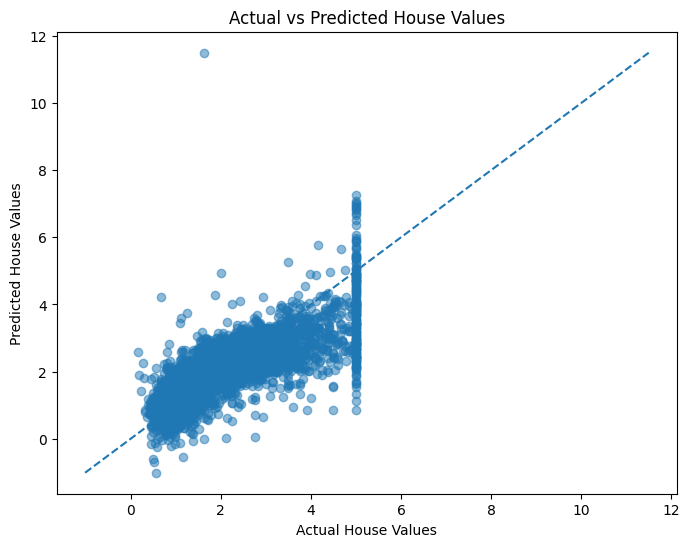

In [8]:
# Step 7: Visualize actual and predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")
plt.show()

## Step 8: Evaluate the model

In [9]:
# Step 8: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nStep 8: Model Performance Evaluation")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R² Score:", round(r2, 4))


Step 8: Model Performance Evaluation
Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R² Score: 0.5758


## Step 9: Analyze regression coefficients


Step 9: Regression Coefficients
      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


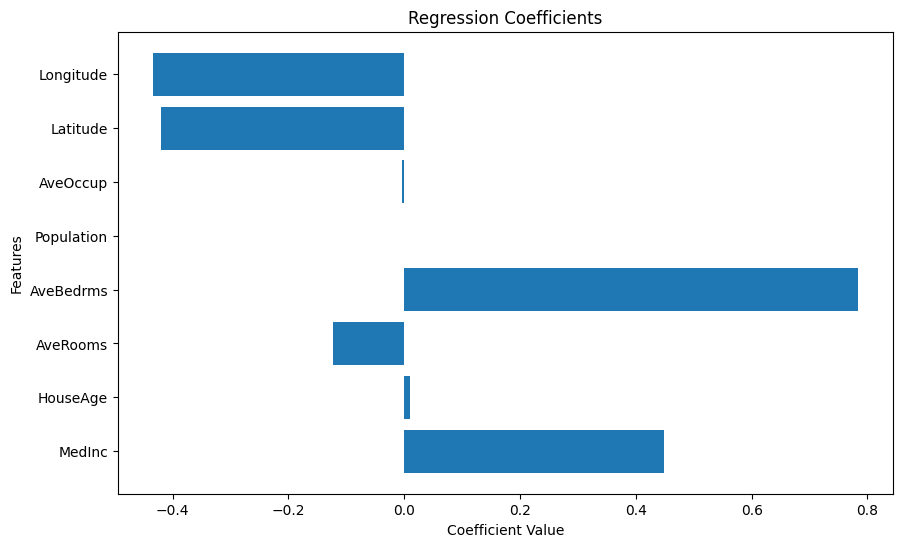

In [10]:
# Step 9: Analyze regression coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nStep 9: Regression Coefficients")
print(coefficients)

plt.figure(figsize=(10, 6))
plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Regression Coefficients")
plt.show()

## Step 10: Interpret and display final result

In [11]:
# Step 10: Interpret and display final result
comparison = pd.DataFrame({
    "Actual Value": y_test.values,
    "Predicted Value": y_pred
})

print("\nStep 10: Actual vs Predicted Values")
print(comparison.head(10))


Step 10: Actual vs Predicted Values
   Actual Value  Predicted Value
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615


## Result / Interpretation

- **R² = 0.5758** → the model explains about 58% of the variation in house values; the rest is unexplained.
- **MAE = 0.5332, RMSE = 0.7456** → on average the predictions are off by roughly 0.53 (in units of $100,000, i.e. about $53,000).
- **Coefficients:** `MedInc` (median income) has a clear positive effect on house value; `Latitude` and `Longitude` are negative (location matters); `AveBedrms` has the largest positive coefficient.
- **Actual vs Predicted plot:** points follow the dashed line loosely, with a vertical band at actual value 5 (values are capped in the dataset) that the model under-predicts.
- **Conclusion:** Linear Regression gives a reasonable baseline for predicting continuous house prices; metrics like MAE, MSE, RMSE and R² show how well it performs.